## **Installation**

Run the following cell to install all required libraries before executing the STEER-LINK circuit, IBM Quantum backend, and visualization cells.

After installation completes, continue running the notebook cells in order.

In [2]:
%pip install -q qiskit qiskit-aer qiskit-ibm-runtime scipy numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 66.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 98.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 75.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 63.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/131.0 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/54

# **STEER-LINK Quantum Circuit**

STEER-LINK is a six-qubit quantum receiver designed to decode 6-bit Pulse Code Modulation (PCM) telemetry words using adaptive quantum operations and classical feed-forward.

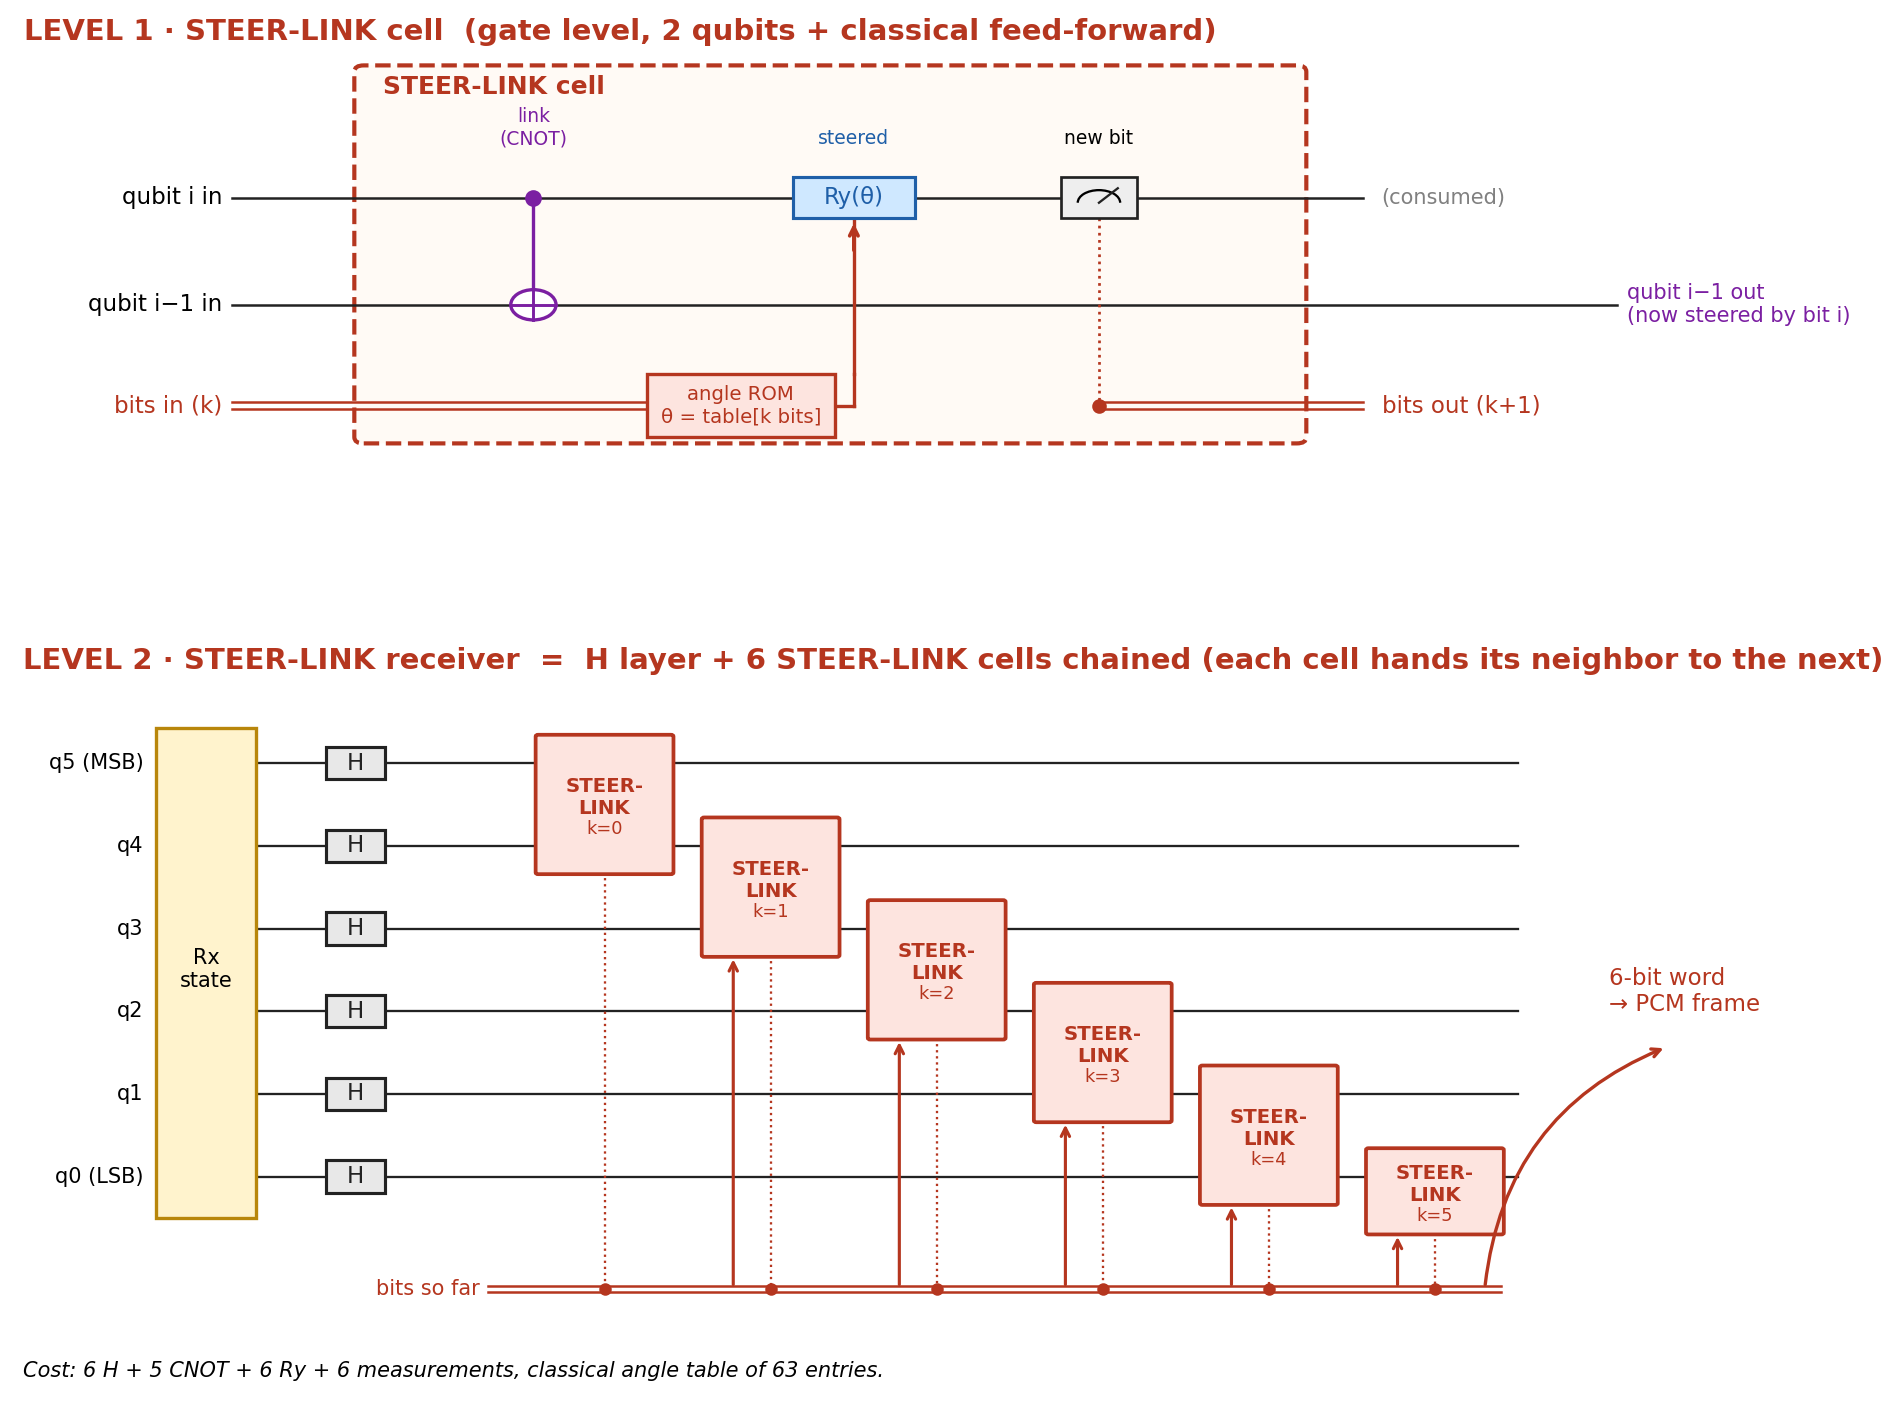

### **Level 1 — STEER-LINK Cell**

Each cell performs three operations:

1. **CNOT Link:** Couples the current qubit to its neighbouring qubit.
2. **Adaptive Rotation:** Applies an \(R_y(\theta)\) gate, where the rotation angle is selected from a classical lookup table (ROM) based on previously measured bits.
3. **Measurement:** Measures the current qubit and passes the resulting classical bit to subsequent cells.

Classical feed-forward allows measurement results to influence subsequent quantum operations.

### **Level 2 — Complete Receiver**

The received six-qubit state passes through a Hadamard layer, followed by six chained STEER-LINK cells. The cells process qubits sequentially from q5 (MSB) to q0 (LSB).

Each cell measures one qubit and updates the classical bit sequence used to select rotation angles for later cells. After all six measurements, the receiver produces a six-bit classical output representing the decoded PCM word.

### **Circuit Resources**

| Component | Count |
|---|---:|
| Hadamard gates | 6 |
| Nearest-neighbour CNOT gates | 5 |
| Adaptive rotation stages | 6 |
| Measurements | 6 |
| Classical angle ROM entries | 63 |

The received-state preparation requires additional gates beyond these receiver resources.

### **Performance Evaluation**

STEER-LINK is compared against the Green Machine baseline, which applies six Hadamard gates followed by six measurements. Word Error Rate (WER) is used to evaluate decoding performance.

Ideal simulation evaluates the circuit without hardware noise. Noisy simulation and quantum-hardware execution help assess the effects of gate errors, measurement errors, and feed-forward constraints. Any performance improvement must be validated using experimental results.

In [6]:
import argparse, json, os, sys, time, warnings

IBM_API_KEY = "API"
IBM_INSTANCE_CRN = "CRN"
IBM_BACKEND = "ibm_marrakesh"

if IBM_API_KEY.startswith("PASTE_") or IBM_INSTANCE_CRN.startswith("PASTE_"):
    raise ValueError("Replace IBM_API_KEY and IBM_INSTANCE_CRN with your actual values.")

import numpy as np
from scipy.optimize import minimize
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector, Operator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

warnings.filterwarnings("ignore")

M = 64
IDX = np.arange(M)
POPC = np.array([bin(i).count("1") for i in range(M)])
WALSH = (-1.0) ** POPC[IDX[:, None] & IDX[None, :]]
CODE_WT = np.where(IDX == 0, 0, np.where(IDX == 1, 32, 16))


def rx_amplitudes(nbar):
    g0 = np.exp(-2 * nbar * CODE_WT)
    lam = WALSH @ g0
    return np.sqrt(np.clip(lam, 0, None)) / 8


def ideal_hadamard_amplitudes(nbar):
    s = rx_amplitudes(nbar)
    return (WALSH * s[None, :]) @ WALSH / 8


def residual_statistics(seed=3, n=200_000):
    rng = np.random.default_rng(seed)
    t = np.arange(n)
    sig = (
        31.5
        + 28 * np.sin(2 * np.pi * t / 300)
        + 6 * np.sin(2 * np.pi * t / 47)
        + rng.normal(0, 0.5, n)
    )
    w = np.clip(np.round(sig), 0, 63).astype(int)
    e = w[1:] ^ w[:-1]
    h = len(e) // 2
    p_learn = np.bincount(e[:h], minlength=M) / h + 1e-4
    p_test = np.bincount(e[h:], minlength=M) / (len(e) - h) + 1e-6
    return p_learn / p_learn.sum(), p_test / p_test.sum()


OFFS = np.cumsum([0] + [2 ** k for k in range(6)])

ANGLE_ROM = {
    0.04: [
        -0.36278, -0.17926, -1.35233, -0.14349, -0.02152, -0.83824, -0.11549,
        -0.12644, -0.02412, -0.12269, -0.29704, -1.11050, -3.23306, -0.11185,
        0.02274, -0.09539, -0.07223, -0.00859, 0.38612, -1.11152, 0.15295,
        0.26132, 0.31939, -0.99176, -0.37267, -2.08350, -0.41511, -0.07969,
        -0.11917, -0.01792, 0.02539, 0.01904, 0.02603, -0.02717, 1.03288,
        0.04964, 0.02753, 0.24605, -0.26926, 0.13724, 3.00432, -0.03947,
        1.32756, -0.24023, -0.67344, -0.06754, 0.28148, 0.28185, -0.28119,
        2.99378, -0.10665, -0.27748, 0.05016, -0.22669, 0.02791, 0.02693,
        0.03158, -0.02964, -0.00996, -0.25187, 0.04719, -0.03398, 0.23569,
    ],
    0.06: [
        -0.14692, -0.10121, -0.08758, -0.07498, -0.01106, -0.26666, 1.68698,
        -0.06836, -0.01766, 3.12246, 0.37736, -1.20708, 0.09702, -0.00350,
        0.35485, -0.04886, -0.06049, 0.06014, 0.20972, 0.01726, 1.97681,
        0.50266, 0.24683, -1.07768, -0.23561, -0.09813, -1.14795, 0.00886,
        0.02819, 0.11509, -0.65549, 0.01236, 0.01475, -0.01462, 0.46525,
        -0.08667, 0.01396, 0.37283, -0.01338, -0.01765, 0.91742, -3.29188,
        0.13144, 0.14516, 0.17364, -0.26338, -0.51542, 0.21043, -0.20945,
        -0.09563, -0.07121, -0.85853, 0.01168, 0.28201, -0.91820, -0.09222,
        -0.08472, 0.08990, 0.07077, 0.12908, 0.49043, -0.50034, -1.05928,
    ],
    0.08: [
        -0.08579, -0.06203, -0.03447, -0.04500, -0.01316, -0.11866, -1.31649,
        -0.04063, -0.02200, 0.00516, 1.35079, -1.15203, 0.04784, -0.17285,
        -0.00265, -0.02836, -0.04156, 0.04610, 1.77649, -1.19355, -0.01711,
        -0.00016, 0.19512, -1.10471, -0.29852, -0.02145, -0.10414, -0.56752,
        0.06177, -0.00367, 0.01935, 0.00570, 0.00662, -0.00665, 0.18084,
        -0.01502, 0.00550, 0.01662, -0.05162, 0.13291, -0.13160, -0.00685,
        0.46007, 0.00570, 0.00787, -0.58781, -0.26950, 0.20425, -0.20233,
        -0.12084, -0.23867, -0.55408, 0.00518, 0.21011, 0.06224, -0.45802,
        0.22439, -0.07653, -0.20677, 0.00865, 0.04502, 0.01356, -0.02155,
    ],
}


def ideal_outcome_probs(theta, A, link=True):
    P = np.zeros((M, M))

    def rec(step, prefix, T):
        i = 5 - step

        if i < 0:
            P[:, prefix] = T[:, 0] ** 2
            return

        if link and i > 0:
            r = np.arange(2 ** (i + 1))
            T = T[:, r ^ (((r >> i) & 1) << (i - 1))]

        th = theta[OFFS[step] + prefix]
        c, s = np.cos(th / 2), np.sin(th / 2)
        T0, T1 = T[:, : 2 ** i], T[:, 2 ** i:]

        rec(step + 1, prefix * 2, c * T0 - s * T1)
        rec(step + 1, prefix * 2 + 1, s * T0 + c * T1)

    rec(0, 0, A.copy())
    return P


def map_decoder(P, prior):
    return np.argmax(prior[:, None] * P, axis=0)


def wer(P, dec, p_true):
    return float((p_true[:, None] * P * (dec[None, :] != IDX[:, None])).sum())


def train_angles(nbar, p_learn, restarts=8, maxiter=300, seed=None):
    A = ideal_hadamard_amplitudes(nbar)

    def f(th):
        P = ideal_outcome_probs(th, A)
        return wer(P, map_decoder(P, p_learn), p_learn)

    rng = np.random.default_rng(int(nbar * 1000) if seed is None else seed)
    best = None

    for r_ in range(restarts):
        res = minimize(
            f,
            rng.normal(0, 0.5, 63),
            method="L-BFGS-B",
            options={"maxiter": maxiter, "maxfun": 20000},
        )
        print(f"  retrain restart {r_}: train WER {res.fun:.4f}", flush=True)

        if best is None or res.fun < best.fun:
            best = res

    return best.x


def get_angles(nbar, retrain, p_learn, prune):
    key = round(nbar, 2)

    if retrain or key not in ANGLE_ROM:
        print(f"training angle ROM for nbar={nbar} ...")
        th = np.array(train_angles(nbar, p_learn))
    else:
        th = np.array(ANGLE_ROM[key], float)

    th = np.where(np.abs(th) <= prune, 0.0, th)
    return th


def staircase_gates(s):
    psi = Statevector(s.astype(complex))
    gens = []

    for k in range(5):
        T = np.moveaxis(
            psi.data.reshape([2] * 6),
            [5 - (k + 1), 5 - k],
            [0, 1],
        )
        L, sv, _ = np.linalg.svd(T.reshape(4, -1), full_matrices=True)
        assert (sv > 1e-10).sum() <= 2, "state is not bond-dimension 2"

        U = np.zeros((4, 4), complex)

        for j, tgt in enumerate([0, 2, 1, 3]):
            U[tgt, :] = L[:, j].conj()

        gens.append((U.conj().T, (k, k + 1)))
        psi = psi.evolve(Operator(U), [k, k + 1])

    return gens[::-1]


def rx_state(nbar, e):
    s = rx_amplitudes(nbar)
    qc = QuantumCircuit(6, name="Rx")

    for G, (a, b) in staircase_gates(s):
        qc.append(UnitaryGate(G), [a, b])

    for i in range(6):
        if (e >> i) & 1:
            qc.z(i)

    return qc


def steer_link_cell(qc, creg, k, theta):
    i = 5 - k

    if i > 0:
        qc.cx(i, i - 1)

    for prefix in range(2 ** k):
        th = float(theta[OFFS[k] + prefix])

        if th == 0.0:
            continue

        if k == 0:
            qc.ry(th, i)
        else:
            with qc.if_test((creg, prefix << (i + 1))):
                qc.ry(th, i)

    qc.measure(i, creg[i])


def steer_link_receiver(theta):
    q, c = QuantumRegister(6, "q"), ClassicalRegister(6, "c")
    qc = QuantumCircuit(q, c, name="STEER-LINK")
    qc.h(range(6))

    for k in range(6):
        steer_link_cell(qc, c, k, theta)

    return qc


def green_machine():
    q, c = QuantumRegister(6, "q"), ClassicalRegister(6, "c")
    qc = QuantumCircuit(q, c, name="GreenMachine")
    qc.h(range(6))
    qc.measure(range(6), range(6))
    return qc


def full_circuit(nbar, e, receiver):
    qc = QuantumCircuit(*receiver.qregs, *receiver.cregs, name=f"{receiver.name}_e{e}")
    qc.compose(rx_state(nbar, e), qubits=range(6), inplace=True)
    qc.compose(receiver, inplace=True)
    return qc


def connect_service():
    from qiskit_ibm_runtime import QiskitRuntimeService

    return QiskitRuntimeService(
        channel="ibm_quantum_platform",
        token=IBM_API_KEY.strip(),
        instance=IBM_INSTANCE_CRN.strip(),
    )


def pick_backend(service, name):
    if name:
        return service.backend(name)

    cands = []

    for kw in (
        {"dynamic_circuits": True, "operational": True, "simulator": False},
        {"operational": True, "simulator": False},
        {},
    ):
        try:
            cands = service.backends(min_num_qubits=6, **kw)
        except Exception:
            continue

        if cands:
            break

    cands = [b for b in cands if not b.simulator and b.status().operational]

    if not cands:
        sys.exit("No operational backend with dynamic-circuit support found for this instance.")

    return min(cands, key=lambda b: b.status().pending_jobs)


def get_backend(args):
    if args.mode == "ideal":
        from qiskit_aer import AerSimulator
        return AerSimulator()

    if args.mode == "noisy":
        from qiskit_ibm_runtime.fake_provider import FakeMarrakesh
        return FakeMarrakesh()

    return pick_backend(connect_service(), args.backend)


def transpile_all(circuits, backend, mode):
    opt = 1 if mode == "ideal" else 3
    pm = generate_preset_pass_manager(
        optimization_level=opt,
        backend=backend,
        seed_transpiler=7,
    )
    layout = None

    if mode != "ideal":
        ref = pm.run(circuits[0])
        layout = ref.layout.initial_index_layout(filter_ancillas=True)
        pm = generate_preset_pass_manager(
            optimization_level=opt,
            backend=backend,
            initial_layout=layout,
            seed_transpiler=7,
        )

    return [pm.run(c) for c in circuits], layout


def circuit_stats(t):
    ops = dict(t.count_ops())
    two_q = sum(v for k, v in ops.items() if k in ("cz", "cx", "ecr"))

    return {
        "depth": t.depth(),
        "two_qubit_gates": two_q,
        "if_blocks": ops.get("if_else", 0),
        "measurements": ops.get("measure", 0),
    }


def execute(circuits, backend, shots, hardware=False):
    from qiskit_ibm_runtime import SamplerV2

    sampler = SamplerV2(mode=backend)
    job = sampler.run(circuits, shots=shots)
    jid = job.job_id() if callable(getattr(job, "job_id", None)) else "local"
    print(f"job id: {jid}   (waiting for results ...)", flush=True)

    res = job.result()
    counts = [r.data.c.get_counts() for r in res]

    if hardware:
        try:
            print(f"QPU usage reported by IBM: {job.usage()} s")
        except Exception:
            pass

    return counts, jid


def counts_to_probs(counts, shots):
    p = np.zeros(M)

    for bits, v in counts.items():
        p[int(bits.replace(" ", ""), 2)] += v

    return p / shots


def noise_sweep(nbar, es, w, theta, P_gm, P_sl, dec_gm, dec_sl, shots):
    from qiskit import transpile
    from qiskit_aer import AerSimulator
    from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

    chain = [[i, i + 1] for i in range(5)] + [[i + 1, i] for i in range(5)]

    print(
        f"\n{'noise':>7s}{'CZ err':>9s}{'readout':>9s}"
        f"{'GM+MAP':>10s}{'STEER-LINK':>12s}{'advantage':>11s}"
    )

    for f in (0.0, 0.1, 0.25, 0.5, 1.0):
        nm = NoiseModel(basis_gates=["cz", "sx", "x", "rz", "id"])
        nm.add_all_qubit_quantum_error(depolarizing_error(f * 0.0035, 2), ["cz"])
        nm.add_all_qubit_quantum_error(depolarizing_error(f * 0.0003, 1), ["sx", "x"])
        nm.add_all_qubit_readout_error(
            ReadoutError([
                [1 - f * 0.015, f * 0.015],
                [f * 0.015, 1 - f * 0.015],
            ])
        )

        sim = AerSimulator(
            noise_model=nm,
            basis_gates=["cz", "sx", "x", "rz", "id", "if_else"],
            coupling_map=chain,
        )

        wer_ = {}

        for name, rec, dec in (
            ("GM", green_machine(), dec_gm),
            ("SL", steer_link_receiver(theta), dec_sl),
        ):
            circs = [
                transpile(
                    full_circuit(nbar, e, rec),
                    sim,
                    optimization_level=3,
                    seed_transpiler=3,
                )
                for e in es
            ]
            res = sim.run(circs, shots=shots).result()

            wer_[name] = sum(
                w[j] * (counts_to_probs(res.get_counts(j), shots) * (dec != e)).sum()
                for j, e in enumerate(es)
            )

        print(
            f"{'x'+str(f):>7s}{f*0.35:8.3f}%{f*1.5:8.2f}%"
            f"{wer_['GM']*100:9.2f}%{wer_['SL']*100:11.2f}%"
            f"{(wer_['GM']-wer_['SL'])*100:+10.2f}pp",
            flush=True,
        )

    print("(depolarizing + readout only: no T1/T2 and no feed-forward latency)")


def main():
    ap = argparse.ArgumentParser(description="STEER-LINK quantum telemetry receiver")
    ap.add_argument("--mode", choices=["ideal", "noisy", "sweep", "hardware"], default="hardware")
    ap.add_argument("--nbar", type=float, default=0.06)
    ap.add_argument("--shots", type=int, default=1000)
    ap.add_argument("--topk", type=int, default=12)
    ap.add_argument("--backend", default=IBM_BACKEND)
    ap.add_argument("--prune", type=float, default=0.05)
    ap.add_argument("--retrain", action="store_true")
    ap.add_argument("--dry-run", action="store_true")
    ap.add_argument("--yes", action="store_true")
    ap.add_argument("--out", default=None)
    args = ap.parse_args(args=[])

    p_learn, p_test = residual_statistics()
    theta = get_angles(args.nbar, args.retrain, p_learn, args.prune)
    A = ideal_hadamard_amplitudes(args.nbar)
    P_gm, P_sl = A ** 2, ideal_outcome_probs(theta, A)
    dec_ml = IDX
    dec_gm = map_decoder(P_gm, p_learn)
    dec_sl = map_decoder(P_sl, p_learn)

    es = [int(x) for x in np.argsort(-p_test)[:args.topk]]
    w = p_test[es] / p_test[es].sum()

    print(
        f"\nnbar={args.nbar} -> {args.nbar*32/6:.2f} photons/bit | "
        f"mode={args.mode} | "
        f"{args.topk} residual words cover {p_test[es].sum()*100:.1f}% of frames | "
        f"{int((theta != 0).sum())}/63 ROM angles active"
    )

    if args.mode == "sweep":
        noise_sweep(
            args.nbar, es, w, theta, P_gm, P_sl,
            dec_gm, dec_sl, max(args.shots, 4000)
        )
        return

    receivers = {"GM": green_machine(), "SL": steer_link_receiver(theta)}
    labels, circuits = [], []

    for e in es:
        for name, rec in receivers.items():
            labels.append((name, e))
            circuits.append(full_circuit(args.nbar, e, rec))

    backend = get_backend(args)
    print(f"backend: {getattr(backend, 'name', backend)}")

    isa, layout = transpile_all(circuits, backend, args.mode)
    st_gm = circuit_stats(isa[labels.index(("GM", es[0]))])
    st_sl = circuit_stats(isa[labels.index(("SL", es[0]))])

    print(f"physical qubits used (q0..q5): {layout}")
    print(f"Green Machine : {st_gm}")
    print(f"STEER-LINK    : {st_sl}")
    print(f"planned: {len(isa)} circuits x {args.shots} shots = {len(isa)*args.shots:,} shots")

    if args.dry_run:
        print("dry run: nothing submitted.")
        return

    if args.mode == "hardware" and not args.yes:
        if input(f"Submit to {backend.name}? [y/N] ").lower() != "y":
            return

    t0 = time.time()
    counts, jid = execute(
        isa,
        backend,
        args.shots,
        hardware=(args.mode == "hardware"),
    )
    print(f"finished in {time.time()-t0:.0f} s wall-clock")

    Ph = {"GM": np.zeros((len(es), M)), "SL": np.zeros((len(es), M))}

    for (name, e), cnt in zip(labels, counts):
        Ph[name][es.index(e)] = counts_to_probs(cnt, args.shots)

    def score(Pmat, dec):
        per_e = np.array([
            (Pmat[j] * (dec != e)).sum()
            for j, e in enumerate(es)
        ])
        return (
            float((w * per_e).sum()),
            float(np.sqrt((w ** 2 * per_e * (1 - per_e) / args.shots).sum())),
        )

    rows = [
        ("Green Machine, plain ML", "GM", dec_ml, P_gm),
        ("Green Machine + MAP", "GM", dec_gm, P_gm),
        ("STEER-LINK + MAP", "SL", dec_sl, P_sl),
    ]

    print(
        f"\n6-bit word error rate at {args.nbar*32/6:.2f} photons/bit "
        f"(on the {args.topk} transmitted residual words)"
    )
    print(f"{'receiver':28s}{'ideal (exact)':>15s}{'this run':>16s}")

    out = {}

    for name, key, dec, Pid in rows:
        ideal = score(Pid[es], dec)[0]
        meas, se = score(Ph[key], dec)
        out[name] = {"ideal": ideal, "measured": meas, "stderr": se}
        print(f"{name:28s}{ideal*100:14.2f}%{meas*100:11.2f}% +/-{se*100:.2f}")

    full = lambda Pm, d: wer(Pm, d, p_test)

    print(
        f"\nideal, all 64 residuals (reference): "
        f"GM plain {full(P_gm, dec_ml)*100:.2f}%  "
        f"GM+MAP {full(P_gm, dec_gm)*100:.2f}%  "
        f"STEER-LINK {full(P_sl, dec_sl)*100:.2f}%"
    )

    gain = out["Green Machine + MAP"]["measured"] - out["STEER-LINK + MAP"]["measured"]

    print(
        f"measured STEER-LINK advantage over Green Machine + MAP: "
        f"{gain*100:+.2f} percentage points "
        f"(ideal: {(out['Green Machine + MAP']['ideal']-out['STEER-LINK + MAP']['ideal'])*100:+.2f})"
    )

    path = args.out or f"steer_link_{args.mode}_{int(time.time())}.json"

    with open(path, "w") as f:
        json.dump(
            {
                "args": vars(args),
                "job_id": jid,
                "residual_words": es,
                "weights": w.tolist(),
                "theta": theta.tolist(),
                "layout": layout,
                "stats": {"GM": st_gm, "SL": st_sl},
                "results": out,
                "counts": [
                    {"receiver": n, "e": e, "counts": c}
                    for (n, e), c in zip(labels, counts)
                ],
            },
            f,
            indent=1,
        )

    print(f"saved {path}")


if __name__ == "__main__":
    main()

qiskit_runtime_service._discover_account:WARNING:2026-10-17 13:41:22,649: Loading account with the given token. A saved account will not be used.



nbar=0.06 -> 0.32 photons/bit | mode=hardware | 12 residual words cover 99.3% of frames | 49/63 ROM angles active
backend: ibm_marrakesh
physical qubits used (q0..q5): [42, 43, 44, 45, 46, 47]
Green Machine : {'depth': 45, 'two_qubit_gates': 10, 'if_blocks': 0, 'measurements': 6}
STEER-LINK    : {'depth': 91, 'two_qubit_gates': 15, 'if_blocks': 48, 'measurements': 6}
planned: 24 circuits x 1000 shots = 24,000 shots
Submit to ibm_marrakesh? [y/N] y
job id: db9nm47i0auc7390vb2g   (waiting for results ...)
QPU usage reported by IBM: 9 s
finished in 15 s wall-clock

6-bit word error rate at 0.32 photons/bit (on the 12 transmitted residual words)
receiver                      ideal (exact)        this run
Green Machine, plain ML               8.29%      22.42% +/-0.64
Green Machine + MAP                   5.77%      16.70% +/-0.49
STEER-LINK + MAP                      5.13%      41.18% +/-0.71

ideal, all 64 residuals (reference): GM plain 8.29%  GM+MAP 5.81%  STEER-LINK 5.21%
measured STE

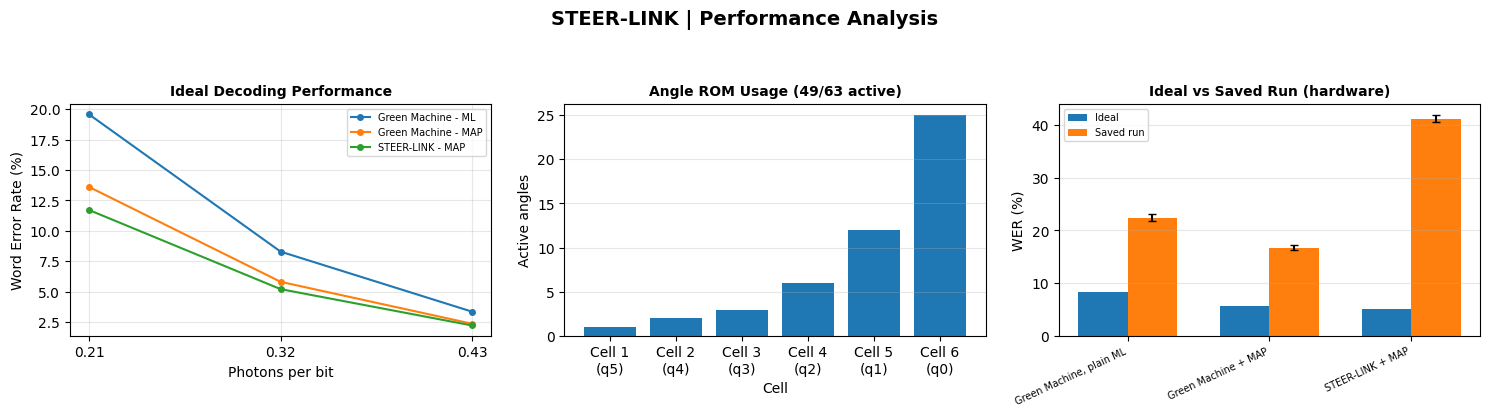




DETAILED STEER-LINK PERFORMANCE RESULTS
Mean photons per code symbol : 0.060
Photons per bit              : 0.3200
Active angle ROM entries     : 49/63
Top 12 residuals cover       : 99.31% of test frames
Saved experiment             : db9nm47i0auc7390vb2g
--------------------------------------------------------------------------------------------------------------
               Receiver  Ideal WER — All 64 (%)  Ideal WER — Top 12 (%)  Saved Ideal WER (%)  Saved Measured WER (%)  Standard Error (%)
Green Machine, plain ML                  8.2918                  8.2918               8.2918                 22.4243              0.6378
    Green Machine + MAP                  5.8135                  5.7706               5.7706                 16.7001              0.4934
       STEER-LINK + MAP                  5.2102                  5.1255               5.1255                 41.1759              0.7061

TOP 12 RESIDUAL WORDS
--------------------------------------------------
 Residu

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import json
import glob
import os

nbar = 0.06
prune = 0.05
photon_levels = [0.04, 0.06, 0.08]

p_learn, p_test = residual_statistics()
theta = get_angles(nbar, False, p_learn, prune)

wer_curves = {
    "Green Machine - ML": [],
    "Green Machine - MAP": [],
    "STEER-LINK - MAP": []
}

for nb in photon_levels:
    A = ideal_hadamard_amplitudes(nb)
    P_gm = A ** 2
    th = get_angles(nb, False, p_learn, prune)
    P_sl = ideal_outcome_probs(th, A)

    dec_ml = IDX
    dec_gm = map_decoder(P_gm, p_learn)
    dec_sl = map_decoder(P_sl, p_learn)

    wer_curves["Green Machine - ML"].append(wer(P_gm, dec_ml, p_test) * 100)
    wer_curves["Green Machine - MAP"].append(wer(P_gm, dec_gm, p_test) * 100)
    wer_curves["STEER-LINK - MAP"].append(wer(P_sl, dec_sl, p_test) * 100)

A = ideal_hadamard_amplitudes(nbar)
P_gm = A ** 2
P_sl = ideal_outcome_probs(theta, A)

dec_ml = IDX
dec_gm = map_decoder(P_gm, p_learn)
dec_sl = map_decoder(P_sl, p_learn)

ideal_models = {
    "Green Machine, plain ML": (P_gm, dec_ml),
    "Green Machine + MAP": (P_gm, dec_gm),
    "STEER-LINK + MAP": (P_sl, dec_sl)
}

saved_report = None

for path in sorted(glob.glob("steer_link_*.json"), key=os.path.getmtime, reverse=True):
    try:
        with open(path) as f:
            candidate = json.load(f)
        if candidate.get("results"):
            saved_report = candidate
            break
    except (OSError, ValueError):
        pass

active_angles = [
    np.count_nonzero(theta[OFFS[k]:OFFS[k + 1]])
    for k in range(6)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
fig.suptitle("STEER-LINK | Performance Analysis", fontsize=14, fontweight="bold")

ax1, ax2, ax3 = axes

for name, values in wer_curves.items():
    ax1.plot(
        [f"{x * 32 / 6:.2f}" for x in photon_levels],
        values, marker="o", markersize=4, linewidth=1.5, label=name
    )

ax1.set_title("Ideal Decoding Performance", fontsize=10, fontweight="bold")
ax1.set_xlabel("Photons per bit")
ax1.set_ylabel("Word Error Rate (%)")
ax1.grid(alpha=0.3)
ax1.legend(fontsize=7)

ax2.bar([f"Cell {k + 1}\n(q{5-k})" for k in range(6)], active_angles)
ax2.set_title(f"Angle ROM Usage ({sum(active_angles)}/63 active)", fontsize=10, fontweight="bold")
ax2.set_xlabel("Cell")
ax2.set_ylabel("Active angles")
ax2.grid(axis="y", alpha=0.3)

if saved_report:
    results = saved_report["results"]
    names = list(results.keys())
    ideal_saved = [results[x]["ideal"] * 100 for x in names]
    measured = [results[x]["measured"] * 100 for x in names]
    errors = [results[x]["stderr"] * 100 for x in names]
    x = np.arange(len(names))
    width = 0.35

    ax3.bar(x - width / 2, ideal_saved, width, label="Ideal")
    ax3.bar(x + width / 2, measured, width, yerr=errors, capsize=3, label="Saved run")
    ax3.set_xticks(x)
    ax3.set_xticklabels(names, rotation=25, ha="right", fontsize=7)
    ax3.set_ylabel("WER (%)")
    ax3.legend(fontsize=7)
    mode = saved_report.get("args", {}).get("mode", "unknown")
    ax3.set_title(f"Ideal vs Saved Run ({mode})", fontsize=10, fontweight="bold")
else:
    ax3.text(0.5, 0.5, "No saved experiment JSON found", ha="center", va="center")
    ax3.set_title("Ideal vs Saved Run", fontsize=10, fontweight="bold")
    ax3.set_xticks([])
    ax3.set_yticks([])

ax3.grid(axis="y", alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig("steer_link_performance_summary.png", dpi=200, bbox_inches="tight")
plt.show()

top = np.argsort(p_test)[-12:][::-1]
saved_results = saved_report.get("results", {}) if saved_report else {}
table_rows = []

for name, (P, dec) in ideal_models.items():
    per_word_error = np.array([
        np.sum(P[e, :] * (dec != e))
        for e in top
    ])

    full_wer = wer(P, dec, p_test) * 100
    top12_wer = (
        np.sum(p_test[top] * per_word_error) / np.sum(p_test[top]) * 100
    )

    row = {
        "Receiver": name,
        "Ideal WER — All 64 (%)": full_wer,
        "Ideal WER — Top 12 (%)": top12_wer,
        "Saved Ideal WER (%)": np.nan,
        "Saved Measured WER (%)": np.nan,
        "Standard Error (%)": np.nan
    }

    if name in saved_results:
        r = saved_results[name]
        row["Saved Ideal WER (%)"] = r["ideal"] * 100
        row["Saved Measured WER (%)"] = r["measured"] * 100
        row["Standard Error (%)"] = r["stderr"] * 100

    table_rows.append(row)

df = pd.DataFrame(table_rows)

print("\n\n")
print("=" * 110)
print("DETAILED STEER-LINK PERFORMANCE RESULTS")
print("=" * 110)
print(f"Mean photons per code symbol : {nbar:.3f}")
print(f"Photons per bit              : {nbar * 32 / 6:.4f}")
print(f"Active angle ROM entries     : {sum(active_angles)}/63")
print(f"Top 12 residuals cover       : {p_test[top].sum() * 100:.2f}% of test frames")
print(f"Saved experiment             : {saved_report.get('job_id', 'N/A') if saved_report else 'No saved results'}")
print("-" * 110)
print(df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("=" * 110)
print("\nTOP 12 RESIDUAL WORDS")
print("-" * 50)
residual_df = pd.DataFrame({
    "Residual Word (Decimal)": top,
    "Residual Word (Binary)": [format(int(e), "06b") for e in top],
    "Test Probability (%)": p_test[top] * 100
})
print(residual_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))